In [15]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

data_dir = Path("data/raw")

for filename in ["CISO.xlsx", "ERCO.xlsx"]:
    path = data_dir / filename
    print(f"{filename}: exists = {path.exists()}")

CISO.xlsx: exists = True
ERCO.xlsx: exists = True


In [16]:
development = {}

for region in ["CISO", "ERCO"]:
    df = pd.read_excel(
        data_dir / f"{region}.xlsx",
        sheet_name="Published Hourly Data",
        usecols=["UTC time", "Demand", "Demand forecast"],
    )

    df = df.rename(columns={
        "UTC time": "timestamp",
        "Demand": "demand",
        "Demand forecast": "operator_forecast",
    })

    df["timestamp"] = pd.to_datetime(df["timestamp"], utc=True)

    # Explore training and validation data only.
    df = df.loc[
        (df["timestamp"] >= "2019-01-01")
        & (df["timestamp"] < "2024-01-01")
    ].copy()

    df = df.sort_values("timestamp").reset_index(drop=True)
    development[region] = df

    print(f"\n{region}")
    print("Rows:", len(df))
    print("First timestamp:", df["timestamp"].min())
    print("Last timestamp:", df["timestamp"].max())
    print("Duplicate timestamps:", df["timestamp"].duplicated().sum())
    print("Missing values:")
    print(df.isna().sum())


CISO
Rows: 43824
First timestamp: 2019-01-01 00:00:00+00:00
Last timestamp: 2023-12-31 23:00:00+00:00
Duplicate timestamps: 0
Missing values:
timestamp             0
operator_forecast     0
demand               22
dtype: int64

ERCO
Rows: 43824
First timestamp: 2019-01-01 00:00:00+00:00
Last timestamp: 2023-12-31 23:00:00+00:00
Duplicate timestamps: 0
Missing values:
timestamp            0
operator_forecast    0
demand               0
dtype: int64


In [17]:
expected_hours = pd.date_range(
    start="2019-01-01",
    end="2024-01-01",
    freq="h",
    inclusive="left",
    tz="UTC",
)

for region, df in development.items():
    actual_hours = pd.DatetimeIndex(df["timestamp"])

    missing_hours = expected_hours.difference(actual_hours)
    unexpected_hours = actual_hours.difference(expected_hours)

    print(f"\n{region}")
    print("Expected hourly timestamps:", len(expected_hours))
    print("Missing hourly timestamps:", len(missing_hours))
    print("Unexpected timestamps:", len(unexpected_hours))

    missing_demand = df.loc[
        df["demand"].isna(), ["timestamp", "demand"]
    ]

    if not missing_demand.empty:
        print("\nRows with missing demand:")
        print(missing_demand.to_string(index=False))


CISO
Expected hourly timestamps: 43824
Missing hourly timestamps: 0
Unexpected timestamps: 0

Rows with missing demand:
                timestamp  demand
2019-02-02 14:00:00+00:00     NaN
2019-02-06 14:00:00+00:00     NaN
2019-06-28 13:00:00+00:00     NaN
2019-07-04 20:00:00+00:00     NaN
2019-07-05 01:00:00+00:00     NaN
2019-08-13 16:00:00+00:00     NaN
2019-08-25 21:00:00+00:00     NaN
2019-09-24 04:00:00+00:00     NaN
2019-11-13 20:00:00+00:00     NaN
2020-02-14 04:00:00+00:00     NaN
2020-03-12 17:00:00+00:00     NaN
2020-08-10 22:00:00+00:00     NaN
2021-08-29 06:00:00+00:00     NaN
2021-08-29 17:00:00+00:00     NaN
2021-08-30 16:00:00+00:00     NaN
2021-08-31 09:00:00+00:00     NaN
2021-08-31 14:00:00+00:00     NaN
2022-01-05 10:00:00+00:00     NaN
2022-05-17 18:00:00+00:00     NaN
2022-06-13 18:00:00+00:00     NaN
2023-10-31 21:00:00+00:00     NaN
2023-11-14 20:00:00+00:00     NaN

ERCO
Expected hourly timestamps: 43824
Missing hourly timestamps: 0
Unexpected timestamps: 0


In [18]:
anomaly_summary = []
flagged_rows = {}

for region, df in development.items():
    demand = df["demand"]

    # Compare adjacent hours without filling missing values.
    hourly_change = demand.pct_change(fill_method=None)
    consecutive = df["timestamp"].diff().eq(pd.Timedelta(hours=1))

    nonpositive = demand.le(0)
    large_jump = (
        hourly_change.abs().gt(0.30)
        & consecutive
        & demand.shift(1).gt(0)
        & demand.gt(0)
    )

    anomaly_summary.append({
        "region": region,
        "minimum_demand": demand.min(),
        "maximum_demand": demand.max(),
        "nonpositive_values": int(nonpositive.sum()),
        "jumps_above_30_percent": int(large_jump.sum()),
    })

    flagged = df.loc[
        nonpositive | large_jump, ["timestamp", "demand"]
    ].copy()
    flagged["hourly_change_percent"] = (
        hourly_change.loc[flagged.index] * 100
    )
    flagged_rows[region] = flagged

display(pd.DataFrame(anomaly_summary))

for region, flagged in flagged_rows.items():
    print(f"\n{region}: first 10 flagged rows")
    display(flagged.head(10))

,region,minimum_demand,maximum_demand,nonpositive_values,jumps_above_30_percent
0,CISO,14.0,51104.0,0,38
1,ERCO,27449.0,85432.0,0,0



CISO: first 10 flagged rows


,timestamp,demand,hourly_change_percent
1050,2019-02-13 18:00:00+00:00,14012.0,-43.017487
1051,2019-02-13 19:00:00+00:00,23928.0,70.767913
1054,2019-02-13 22:00:00+00:00,14112.0,-42.253867
1055,2019-02-13 23:00:00+00:00,24732.0,75.255102
1076,2019-02-14 20:00:00+00:00,15095.0,-41.492248
1077,2019-02-14 21:00:00+00:00,24977.0,65.465386
1078,2019-02-14 22:00:00+00:00,14616.0,-41.482164
1082,2019-02-15 02:00:00+00:00,24873.0,77.372887
1194,2019-02-19 18:00:00+00:00,13519.0,-42.873442
1195,2019-02-19 19:00:00+00:00,21447.0,58.643391



ERCO: first 10 flagged rows


,timestamp,demand,hourly_change_percent


Readings surrounding CAISO's minimum:


,timestamp,operator_forecast,demand
8469,2019-12-19 21:00:00+00:00,23380.0,23285.0
8470,2019-12-19 22:00:00+00:00,23445.0,23393.0
8471,2019-12-19 23:00:00+00:00,23942.0,23843.0
8472,2019-12-20 00:00:00+00:00,24683.0,14.0
8473,2019-12-20 01:00:00+00:00,26545.0,91.0
8474,2019-12-20 02:00:00+00:00,29425.0,96.0
8475,2019-12-20 03:00:00+00:00,29728.0,29637.0


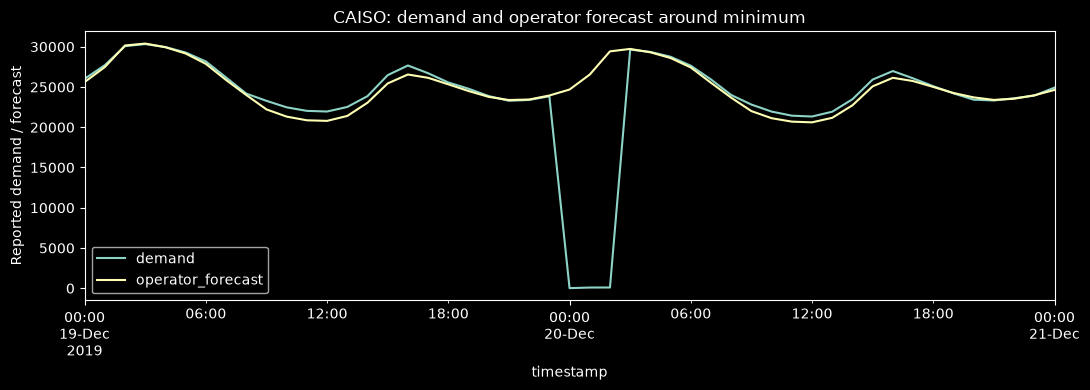

In [19]:
ciso = development["CISO"]
lowest_index = ciso["demand"].idxmin()

print("Readings surrounding CAISO's minimum:")
display(ciso.iloc[
    max(0, lowest_index - 3):lowest_index + 4
])

center = ciso.loc[lowest_index, "timestamp"]

window = ciso.loc[
    ciso["timestamp"].between(
        center - pd.Timedelta(hours=24),
        center + pd.Timedelta(hours=24),
    )
]

ax = window.plot(
    x="timestamp",
    y=["demand", "operator_forecast"],
    figsize=(11, 4),
    title="CAISO: demand and operator forecast around minimum",
)
ax.set_ylabel("Reported demand / forecast")
plt.tight_layout()
plt.show()

In [20]:
time_zones = {
    "CISO": "America/Los_Angeles",
    "ERCO": "America/Chicago",
}

time_checks = []

for region, df in development.items():
    zone = time_zones[region]
    local_time = df["timestamp"].dt.tz_convert(zone)
    daily_counts = local_time.dt.date.value_counts()

    spring_date = pd.Timestamp("2023-03-12").date()
    fall_date = pd.Timestamp("2023-11-05").date()

    time_checks.append({
        "region": region,
        "UTC timezone": str(df["timestamp"].dt.tz),
        "intervals other than 1 hour": int(
            df["timestamp"].diff().iloc[1:]
            .ne(pd.Timedelta(hours=1)).sum()
        ),
        "spring day hours": int(daily_counts.get(spring_date, 0)),
        "fall day hours": int(daily_counts.get(fall_date, 0)),
    })

display(pd.DataFrame(time_checks))

,region,UTC timezone,intervals other than 1 hour,spring day hours,fall day hours
0,CISO,UTC,0,23,25
1,ERCO,UTC,0,23,25


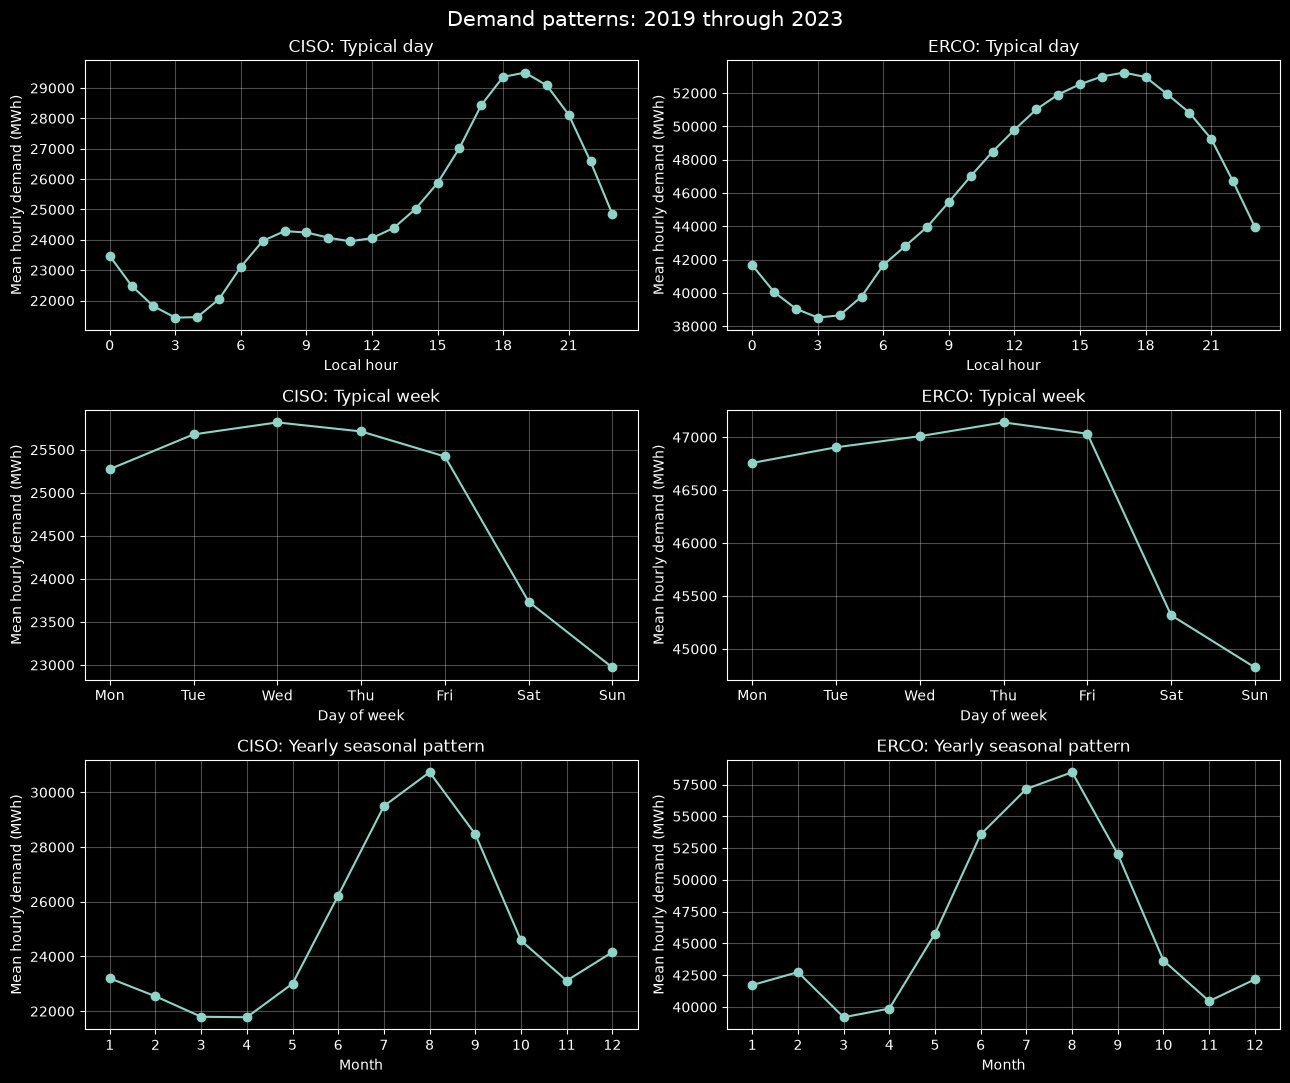

In [21]:
fig, axes = plt.subplots(3, 2, figsize=(13, 11))

for column, (region, df) in enumerate(development.items()):
    plot_data = df.copy()

    # Shift hour-ending timestamps to the start of each interval
    # before assigning local calendar features.
    local_time = (
        plot_data["timestamp"] - pd.Timedelta(hours=1)
    ).dt.tz_convert(time_zones[region])

    plot_data["hour"] = local_time.dt.hour
    plot_data["weekday"] = local_time.dt.day_of_week
    plot_data["month"] = local_time.dt.month

    patterns = [
        ("hour", "Typical day", "Local hour"),
        ("weekday", "Typical week", "Day of week"),
        ("month", "Yearly seasonal pattern", "Month"),
    ]

    for row, (feature, title, xlabel) in enumerate(patterns):
        average = plot_data.groupby(feature)["demand"].mean()
        ax = axes[row, column]

        ax.plot(average.index, average.values, marker="o")
        ax.set_title(f"{region}: {title}")
        ax.set_xlabel(xlabel)
        ax.set_ylabel("Mean hourly demand (MWh)")
        ax.grid(alpha=0.3)

    axes[0, column].set_xticks(range(0, 24, 3))

    axes[1, column].set_xticks(
        range(7),
        ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"],
    )

    axes[2, column].set_xticks(range(1, 13))

fig.suptitle("Demand patterns: 2019 through 2023", fontsize=15)
plt.tight_layout()
plt.show()

### Data audit findings

I audited hourly electricity demand and operator forecasts for CAISO and ERCOT from January 2019 through December 2023. Each region has 43,824 rows and no duplicate timestamps. CAISO is missing 22 demand readings, about 0.05% of its records. ERCOT is missing none. Both regions have an operator forecast for every row.

Timestamps run continuously by the hour in UTC. Converting to local time gives 23 hours on the 2023 spring daylight saving transition and 25 on the fall transition. I will store everything in UTC and build local calendar features from it, so daily and weekly patterns follow local time.

I screened for hourly demand changes above 30%. CAISO has 38 flags and ERCOT has none. The clearest case is December 20, 2019, where readings of 14, 91, and 96 sit between readings near 24,000 and 30,000. That looks like a reporting error, but I have not verified the cause. The original values stay untouched. I will check each flag against the source documentation before choosing a cleaning rule. Missing target values drop out of supervised training and scoring.

The plots show demand falling overnight, rising during the day, and averaging lower on weekends. CAISO's typical daily peak comes later than ERCOT's. Both regions hit their highest monthly average in August. Hour, weekday, and season features should give the models something real to learn from.

I split the data chronologically: 2019 through 2022 for training, 2023 for validation, and 2024 through 2025 for the final test. I have kept the final test demand out of all exploratory analysis. Once I settle on model settings, I will refit the final models on the development data through 2023.

### Data source and limitations

Source: U.S. Energy Information Administration, Form EIA-930 Hourly Electric Grid Monitor.

Files accessed on November 16, 2026:
* [CISO.xlsx](https://www.eia.gov/electricity/gridmonitor/knownissues/xls/CISO.xlsx)
* [ERCO.xlsx](https://www.eia.gov/electricity/gridmonitor/knownissues/xls/ERCO.xlsx)

I used the Published Hourly Data sheet. Demand and operator forecasts are in MWh. Each UTC timestamp marks the end of its hourly interval, so for the local pattern plots I shift timestamps back one hour before assigning calendar features.

EIA labels the data preliminary and subject to revision. I kept the original workbooks as downloaded. Source details and reuse terms are on the [EIA Grid Monitor documentation](https://www.eia.gov/electricity/930-content/about.html) and the [EIA copyright and reuse page](https://www.eia.gov/about/copyrights_reuse.php).

Reading the documentation tabs triggered warnings about malformed Excel date cells. I have not verified the cause of the suspicious December 2019 CAISO demand readings.

In [22]:
import json
from pathlib import Path

split_config = {
    "timezone": "UTC",
    "boundary_convention": "start inclusive, end exclusive",
    "regions": ["CISO", "ERCO"],
    "train": {
        "start": "2019-01-01",
        "end": "2023-01-01",
    },
    "validation": {
        "start": "2023-01-01",
        "end": "2024-01-01",
    },
    "test": {
        "start": "2024-01-01",
        "end": "2026-01-01",
    },
}

split_path = Path("splits.json")

if split_path.exists():
    existing = json.loads(split_path.read_text())
    if existing != split_config:
        raise ValueError("Existing split dates differ. Review before changing.")
else:
    split_path.write_text(json.dumps(split_config, indent=2))

print("Split configuration saved:", split_path.resolve())

Split configuration saved: C:\CSC 4880\mlfinalproject\electricity-demand-forecasting\splits.json
